# Brazil is not binary: exploratory analysis

Presidential elections 2018, 2022 and 2026 (2014 as a baseline), municipality level.
Data: TSE open data (votes and turnout by municipality and zone), IBGE (mesh, population, income).
Every table read here is produced by `python run_all.py` (one SQL file per question in `sql/`).

**Camps.** Lulista = Haddad 2018, Lula 2022 and 2026. Bolsonarista = Jair Bolsonaro 2018 and 2022,
Flávio Bolsonaro 2026. In 2014 the runoff was Dilma (PT) against Aécio (PSDB); it is used only as a
baseline and labelled by name.

**Caveat.** Municipal data describe places, not people. Associations between municipal measures
do not tell how any individual voted (ecological fallacy).

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P = ROOT / "data" / "processed"
facts = json.loads((ROOT / "docs" / "data" / "facts.json").read_text(encoding="utf-8"))
L, B, MIX, GREY = "#6A4C9C", "#B8741A", "#E9C3C4", "#9A9186"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


## Q1. National results, including people who chose neither camp

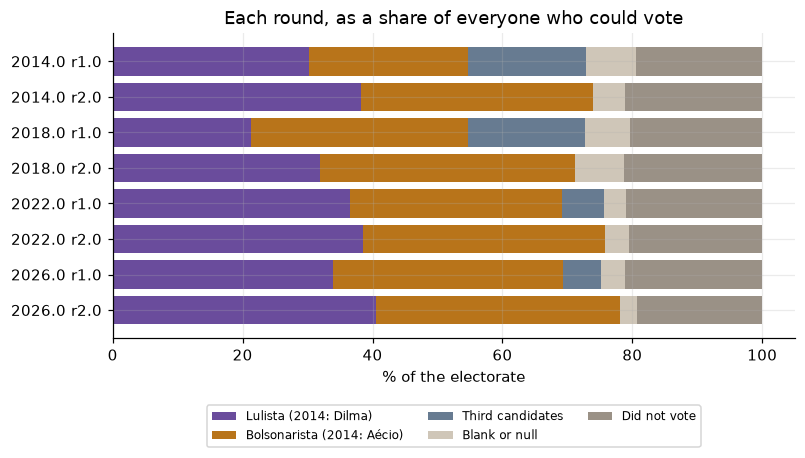

,year,round,aptos,camp_l,camp_b,others,blank_null,absent,pct_l_valid,pct_b_valid,pct_neither_aptos
0,2014,1,"142,822,000.000","43,267,700.000","34,897,200.000","25,858,900.000","11,099,100.000","27,699,200.000",0.416,0.335,0.453
1,2014,2,"142,822,000.000","54,501,100.000","51,041,200.000",0.000,"7,141,610.000","30,138,200.000",0.516,0.484,0.261
2,2018,1,"147,306,000.000","31,342,100.000","49,277,000.000","26,431,700.000","10,313,900.000","29,941,600.000",0.293,0.460,0.453
3,2018,2,"147,306,000.000","47,040,900.000","57,797,800.000",0.000,"11,094,700.000","31,372,800.000",0.449,0.551,0.288
4,2022,1,"156,454,000.000","57,259,500.000","51,072,300.000","9,897,870.000","5,452,650.000","32,771,600.000",0.484,0.432,0.308
5,2022,2,"156,454,000.000","60,346,000.000","58,206,400.000",0.000,"5,700,440.000","32,201,200.000",0.509,0.491,0.242
6,2026,1,"158,746,000.000","53,879,500.000","56,104,500.000","9,316,750.000","5,975,050.000","33,469,700.000",0.452,0.470,0.307
7,2026,2,"158,746,000.000","64,256,200.000","59,826,000.000",0.000,"4,153,800.000","30,509,400.000",0.518,0.482,0.218


In [2]:
nat = pd.read_csv(P / "q1_national.csv")
cols = ["pct_l_aptos", "pct_b_aptos", "pct_others_aptos", "pct_blank_null_aptos", "pct_absent_aptos"]
labels = ["Lulista (2014: Dilma)", "Bolsonarista (2014: Aécio)", "Third candidates", "Blank or null", "Did not vote"]
colors = [L, B, "#677B91", "#CFC6B8", GREY]
fig, ax = plt.subplots(figsize=(8, 3.6))
y = [f"{r.year} r{r['round']}" for _, r in nat.iterrows()]
left = [0] * len(nat)
for c, lab, col in zip(cols, labels, colors):
    ax.barh(y, nat[c] * 100, left=left, color=col, label=lab)
    left = [l + v * 100 for l, v in zip(left, nat[c])]
ax.invert_yaxis(); ax.set_xlabel("% of the electorate"); ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.set_title("Each round, as a share of everyone who could vote")
plt.show()
nat[["year", "round", "aptos", "camp_l", "camp_b", "others", "blank_null", "absent", "pct_l_valid", "pct_b_valid", "pct_neither_aptos"]]

**Takeaways**

* 2026 runoff: Lula 51.8% and Flávio Bolsonaro 48.2% of valid votes.
* 21.8% of the electorate did not vote for either candidate in the 2026 runoff:
  19.2% did not turn out and 2.6% voted blank or null. Abstention also
  includes registered voters who moved or died, so it is not all a choice.
* 2026 first round: Flávio 47.0%, Lula 45.2%, and 9.3 million votes for third candidates.

## Q2. Municipal results: who led where

In [3]:
win = pd.read_csv(P / "q2_winners.csv")
win[["year", "round", "led_by_l", "led_by_b", "ties", "aptos_share_in_l_led", "l_votes_where_b_led", "b_votes_where_l_led"]]

,year,round,led_by_l,led_by_b,ties,aptos_share_in_l_led,l_votes_where_b_led,b_votes_where_l_led
0,2014,1,3648,1821,2,0.484,"12,190,900.000","11,409,200.000"
1,2014,2,3527,2043,0,0.513,"19,457,100.000","18,047,300.000"
2,2018,1,2614,2852,1,0.258,"14,516,600.000","6,397,160.000"
3,2018,2,2810,2760,0,0.319,"23,264,700.000","10,193,200.000"
4,2022,1,3376,2191,3,0.499,"21,373,400.000","18,615,600.000"
5,2022,2,3123,2445,2,0.468,"24,658,600.000","19,547,900.000"
6,2026,1,2663,2906,2,0.431,"22,886,900.000","17,305,600.000"
7,2026,2,2875,2695,1,0.500,"24,255,900.000","22,297,400.000"


**Takeaways**

* 2026 runoff: Lula led in 2,875 municipalities and Flávio in 2,695.
  The electorate living in municipalities led by each is almost exactly split (50.0% and 50.0%).
* 24.3 million Lula votes came from municipalities where Flávio led, and 22.3 million
  Flávio votes from municipalities where Lula led.
* In 5,558 of 5,571 municipalities the side that lost locally still got more than 10%.
* First rounds: a third candidate came first in 99 municipalities in 2014 (Marina Silva) and
  103 in 2018 (Ciro Gomes); in 2022 and 2026, in 0.

## Q3. How mixed is the vote?

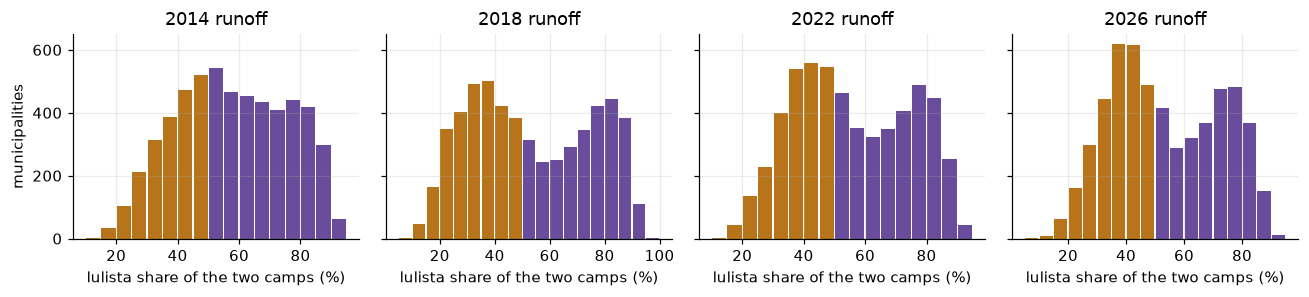

,year,round,n_minority_over_30,share_minority_over_30,n_minority_over_40,aptos_share_minority_over_30,local_minority_votes,local_minority_vote_share,min_minority_share
0,2014,1,3127,0.562,1788,0.648,"25,745,400.000",0.330,0.018
1,2014,2,3587,0.644,1997,0.740,"37,504,400.000",0.356,0.061
2,2018,1,2474,0.444,1129,0.403,"21,508,900.000",0.267,0.020
3,2018,2,2898,0.520,1361,0.617,"33,458,000.000",0.320,0.020
4,2022,1,3441,0.618,1953,0.774,"39,989,000.000",0.370,0.057
5,2022,2,3521,0.632,1913,0.780,"44,206,600.000",0.374,0.061
6,2026,1,3405,0.611,1564,0.751,"40,192,500.000",0.366,0.078
7,2026,2,3554,0.638,1804,0.787,"46,553,300.000",0.376,0.077


In [4]:
h = pd.read_csv(P / "q3_hist.csv")
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
for ax, yr in zip(axes, [2014, 2018, 2022, 2026]):
    d = h[(h.year == yr) & (h["round"] == 2)]
    ax.bar(d.bin_start_pct + 2.5, d.municipalities, width=4.6,
           color=[L if b >= 50 else B for b in d.bin_start_pct])
    ax.set_title(f"{yr} runoff"); ax.set_xlabel("lulista share of the two camps (%)")
axes[0].set_ylabel("municipalities")
plt.tight_layout(); plt.show()
mino = pd.read_csv(P / "q3_minority.csv")
mino[["year", "round", "n_minority_over_30", "share_minority_over_30", "n_minority_over_40", "aptos_share_minority_over_30", "local_minority_votes", "local_minority_vote_share", "min_minority_share"]]

In [5]:
reg = pd.read_csv(P / "q3_region.csv")
reg[(reg.year == 2026) & (reg["round"] == 2)][["region", "municipalities", "camp_l", "camp_b", "share_l2", "led_by_l", "led_by_b"]]

,region,municipalities,camp_l,camp_b,share_l2,led_by_l,led_by_b
42,Norte,450,"5,024,630.000","5,023,550.000",0.500,267,183
43,Nordeste,1794,"24,450,400.000","10,796,700.000",0.694,1774,20
44,Sudeste,1668,"24,037,700.000","26,844,500.000",0.472,636,1032
45,Sul,1191,"6,809,370.000","11,385,900.000",0.374,136,1054
46,Centro-Oeste,468,"3,733,920.000","5,603,870.000",0.400,62,406
47,Exterior,0,"200,154.000","171,497.000",0.539,0,0


In [6]:
pd.read_csv(P / "q3_extremes.csv").query("round == 2")[["year", "kind", "name", "uf", "aptos", "camp_l", "camp_b", "share_l2"]]

,year,kind,name,uf,aptos,camp_l,camp_b,share_l2
4,2014,most_l,Belágua,MA,5157,3558,230,0.939
5,2014,most_l_100k,Caxias,MA,107693,61672,11415,0.844
6,2014,most_b_100k,Bragança Paulista,SP,117990,18003,72117,0.200
7,2014,most_b,Nova Pádua,RS,2144,222,1650,0.119
12,2018,most_l,Guaribas,PI,3575,2879,59,0.980
13,2018,most_l_100k,Juazeiro do Norte,CE,169155,101288,31793,0.761
14,2018,most_b_100k,Blumenau,SC,244336,31090,162622,0.160
15,2018,most_b,Nova Pádua,RS,2308,134,1770,0.070
20,2022,most_b_100k,Boa Vista,RR,233102,37412,144799,0.205
21,2022,most_l_100k,Caxias,MA,108400,65194,19276,0.772


**Takeaways**

* 2026 runoff: 46.6 million people (37.6% of valid votes) voted for the
  candidate who lost in their own municipality.
* In 3,554 municipalities (63.8%) the local loser still got more than 30%;
  in 1,804 (32.4%), more than 40%.
* Even the most one-sided places are mixed: in Carnaubeira da Penha (PE) Flávio got 7.7%;
  in Nova Pádua (RS) Lula got 9.4%.
* Flávio got 10.8 million votes in the Northeast, more than in 11 states of other regions
  combined. Lula got 6.8 million in the South, more than in 11 states of other regions combined.
* In the North the two were 1,079 votes apart.
* Against the thesis, regions are not mirror images: in the Northeast Lula led 1,774 of
  1,794 municipalities; in the South Flávio led 1,054 of 1,191,
  and in the Center-West 406 of 468.
* Lula's lead in the Northeast was 13.7 million votes; Flávio's leads in Southeast, South and Center-West added up to
  9.3 million.

## Q4. 2018: growth of the bolsonarista camp over the non-PT side of 2014

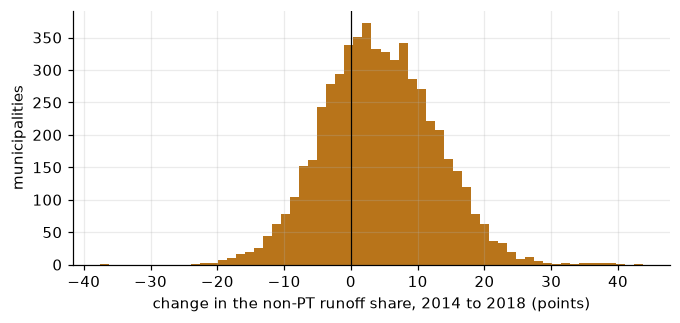

,year,region_id,region,b_share_r2
0,2014,1,Norte,0.435
1,2014,2,Nordeste,0.283
2,2014,3,Sudeste,0.562
3,2014,4,Sul,0.589
4,2014,5,Centro-Oeste,0.574
5,2018,1,Norte,0.519
6,2018,2,Nordeste,0.303
7,2018,3,Sudeste,0.654
8,2018,4,Sul,0.683
9,2018,5,Centro-Oeste,0.665


,name,uf,aptos_2018,b_share_2014_r2,b_share_2018_r2,delta_b_r2
0,Belford Roxo,RJ,331030,0.252,0.689,0.437
1,Queimados,RJ,72959,0.280,0.685,0.404
2,Japeri,RJ,73653,0.276,0.665,0.388
3,Itaboraí,RJ,171832,0.274,0.660,0.386
4,Duque de Caxias,RJ,634613,0.309,0.688,0.378
5,São João de Meriti,RJ,367702,0.340,0.715,0.375
6,Nova Iguaçu,RJ,588320,0.361,0.725,0.363
7,Itaguaí,RJ,90916,0.390,0.750,0.359
8,Mesquita,RJ,135061,0.359,0.717,0.358
9,São Gonçalo,RJ,678364,0.320,0.674,0.354


In [7]:
q4 = pd.read_csv(P / "q4_municipal.csv")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(q4.delta_b_r2 * 100, bins=60, color=B)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("change in the non-PT runoff share, 2014 to 2018 (points)"); ax.set_ylabel("municipalities")
plt.show()
display(pd.read_csv(P / "q4_region_share.csv"))
pd.read_csv(P / "q4_top.csv")[["name", "uf", "aptos_2018", "b_share_2014_r2", "b_share_2018_r2", "delta_b_r2"]].head(10)

**Takeaways**

* The non-PT runoff share grew in 3,830 municipalities (68.8%); 775 municipalities that
  Dilma led in 2014 were led by Bolsonaro in 2018.
* The non-PT runoff share rose by 8.4 points in the North, 9.2 points in the Southeast,
  9.4 points in the South and 9.1 points in the Center-West, and by 2.0 points in the Northeast.
  Different candidates (Aécio, then Bolsonaro): this measures the side opposed to the PT, not one movement.
* Nationally, Bolsonaro had 6.8 million more runoff votes than Aécio; Haddad had −7.5 million relative to Dilma.
* Of the ten largest increases among municipalities with 50,000+ voters, 10 were in Rio de Janeiro state;
  the largest was Belford Roxo (RJ), 43.7 points.

## Q5. 2022: where the lulista camp regained ground

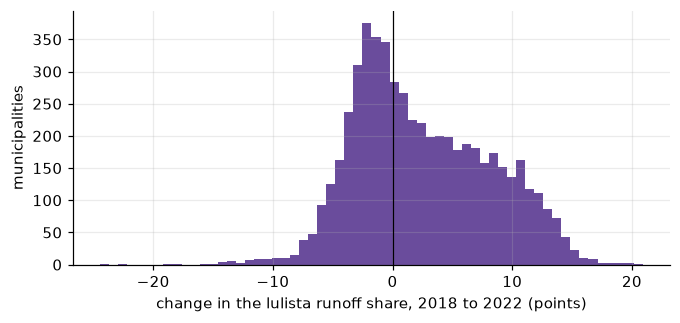

,region,delta_l_share_region,delta_l_votes_r2,delta_b_votes_r2,share_mun_l_grew,n_flipped_to_l
0,Norte,0.009,"657,169.000","539,837.000",0.249,9
1,Nordeste,-0.003,"2,245,160.000","1,138,490.000",0.205,9
2,Sudeste,0.111,"7,777,590.000","-1,307,860.000",0.941,263
3,Sul,0.064,"1,597,690.000","-144,237.000",0.772,61
4,Centro-Oeste,0.063,"928,317.000","168,685.000",0.711,26


,name,uf,aptos_2022,l_share_2018_r2,l_share_2022_r2,delta_l_r2
0,Cruzeiro,SP,60216,0.235,0.405,0.170
1,São Roque,SP,63512,0.268,0.437,0.169
2,Ribeirão Pires,SP,90834,0.333,0.487,0.154
3,São Carlos,SP,195010,0.327,0.480,0.153
4,Mauá,SP,315821,0.379,0.532,0.153
5,Botucatu,SP,107506,0.264,0.416,0.152
6,Santos,SP,353566,0.286,0.438,0.152
7,Pindamonhangaba,SP,122417,0.210,0.360,0.151
8,Jacareí,SP,176960,0.223,0.374,0.151
9,São Caetano do Sul,SP,146352,0.249,0.399,0.150


In [8]:
q5 = pd.read_csv(P / "q5_municipal.csv")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(q5.delta_l_r2 * 100, bins=60, color=L)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("change in the lulista runoff share, 2018 to 2022 (points)"); ax.set_ylabel("municipalities")
plt.show()
display(pd.read_csv(P / "q5_region.csv")[["region", "delta_l_share_region", "delta_l_votes_r2", "delta_b_votes_r2", "share_mun_l_grew", "n_flipped_to_l"]])
pd.read_csv(P / "q5_top.csv")[["name", "uf", "aptos_2022", "l_share_2018_r2", "l_share_2022_r2", "delta_l_r2"]].head(10)

**Takeaways**

* The lulista runoff share grew in 3,300 municipalities (59.2%); 368 flipped to Lula and 54 to Bolsonaro.
* Lula had 13.3 million more runoff votes than Haddad; Bolsonaro had 409,000 more than in 2018.
* The recovery was mostly in the Southeast (+11.1 points), which accounts for 58.9% of Lula's vote gain;
  the Northeast barely moved (−0.3 points).

## Q6. 2026: the runoff turnaround

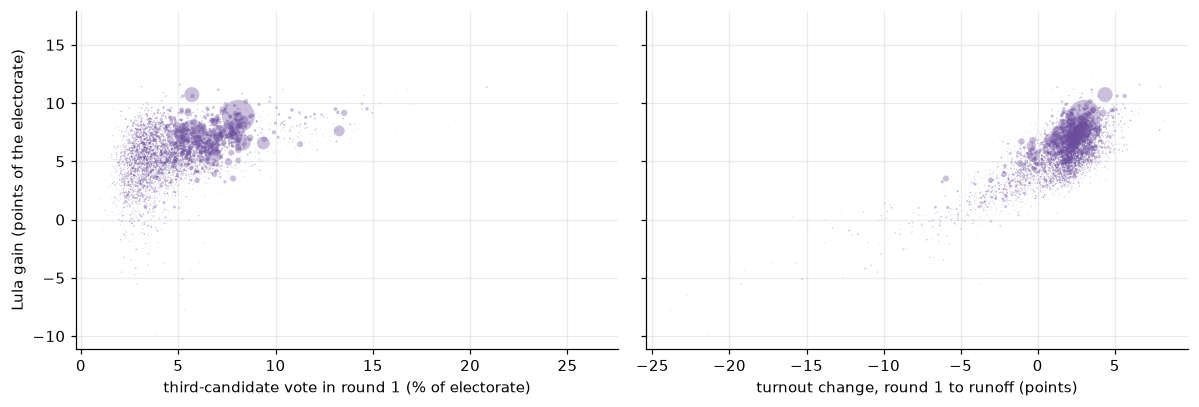

,outcome,factor,r_weighted,r_unweighted
0,gain_l_pts,blank_null_change_pts,-0.402,-0.426
1,gain_l_pts,others_r1_pts,0.483,0.367
2,gain_b_pts,others_r1_pts,0.765,0.679
3,gain_l_pts,turnout_change_pts,0.714,0.699
4,gain_b_pts,turnout_change_pts,0.579,0.608


,factor,quintile,municipalities,factor_min,factor_max,gain_l_pts_weighted,gain_b_pts_weighted,net_gain_l_pts_weighted,gain_l_pts_median,gain_b_pts_median
0,others_r1_pts,1,1115,0.010,0.031,0.045,0.002,0.043,0.045,0.002
1,others_r1_pts,2,1114,0.031,0.038,0.053,0.006,0.047,0.052,0.009
2,others_r1_pts,3,1114,0.038,0.048,0.058,0.014,0.044,0.053,0.018
3,others_r1_pts,4,1114,0.048,0.060,0.068,0.021,0.047,0.057,0.028
4,others_r1_pts,5,1114,0.060,0.263,0.073,0.035,0.037,0.065,0.039
5,turnout_change_pts,1,1115,-0.238,-0.000,0.037,-0.002,0.039,0.031,-0.004
6,turnout_change_pts,2,1114,-0.000,0.015,0.058,0.018,0.040,0.051,0.014
7,turnout_change_pts,3,1114,0.015,0.022,0.065,0.028,0.037,0.055,0.026
8,turnout_change_pts,4,1114,0.022,0.029,0.069,0.030,0.039,0.061,0.027
9,turnout_change_pts,5,1114,0.029,0.082,0.079,0.028,0.051,0.066,0.027


,delta_l_votes,delta_b_votes,others_r1,delta_turnout,delta_blank_null,b_lead_r1,l_lead_r2
0,"10,376,700.000","3,721,540.000","9,316,750.000","2,960,240.000","-1,821,250.000","2,224,960.000","4,430,190.000"


In [9]:
q6 = pd.read_csv(P / "q6_municipal.csv")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, x, lab in ((axes[0], "others_r1_pts", "third-candidate vote in round 1 (% of electorate)"),
                   (axes[1], "turnout_change_pts", "turnout change, round 1 to runoff (points)")):
    ax.scatter(q6[x] * 100, q6.gain_l_pts * 100, s=q6.aptos / 20000, alpha=0.35, color=L, lw=0)
    ax.set_xlabel(lab)
axes[0].set_ylabel("Lula gain (points of the electorate)")
plt.tight_layout(); plt.show()
display(pd.read_csv(P / "q6_assoc.csv"))
display(pd.read_csv(P / "q6_bins.csv"))
pd.read_csv(P / "q6_national.csv")

**Takeaways**

* Flávio led the first round by 2.2 million votes; Lula won the runoff by 4.4 million.
* Between rounds Lula gained 10.4 million votes and Flávio 3.7 million. Third candidates had 9.3 million votes in
  round 1, turnout rose by 3.0 million and blank or null votes fell by 1.8 million.
* Lula grew more than Flávio (in points of the electorate) in 5,230 of 5,571 municipalities, Flávio more than Lula
  in 340; 211 flipped to Lula and 1 to Flávio (Uirapuru (GO)).
* Largest gains among municipalities with 50,000+ voters: Lula in Mariana (MG) (11.2 points), Flávio in
  Trindade (GO) (7.6 points).
* Where third candidates had more votes in round 1, both candidates grew more in the runoff; where turnout rose more, too.
  Part of this is arithmetic: in points of the electorate, the two gains add up to the third-candidate vote plus the turnout
  change minus the change in blank/null votes. Lula's net advantage grew by a similar amount everywhere, from 3.7 points
  to 5.1 points across groups of municipalities. Municipal data do not show who switched votes.

## Q7. Size, region and income: overlapping distributions

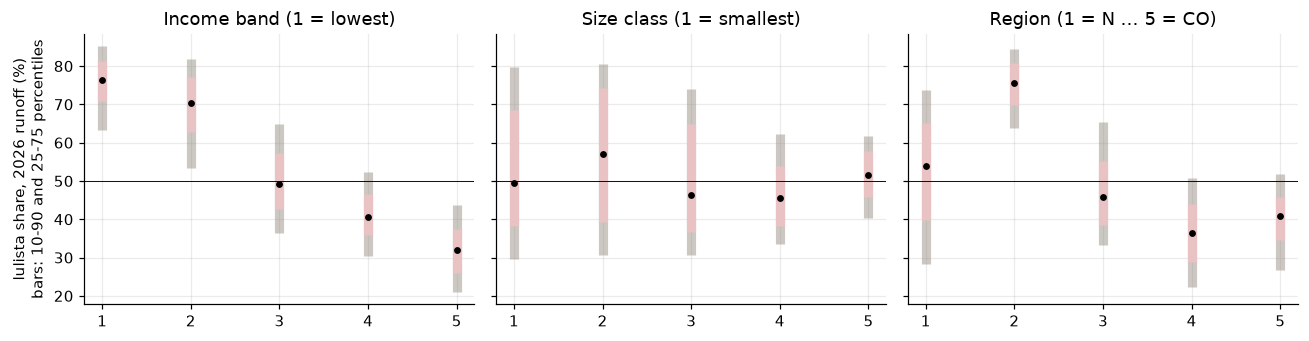

,dimension,grp,municipalities,p10,p50,p90,led_by_l,led_by_b
45,income,1,1114,0.633,0.764,0.851,1082,32
46,income,2,1118,0.534,0.705,0.817,1034,84
47,income,3,1110,0.363,0.493,0.649,527,583
48,income,4,1392,0.305,0.406,0.524,208,1183
49,income,5,836,0.211,0.319,0.437,24,812
50,region,1,450,0.282,0.539,0.737,267,183
51,region,2,1794,0.638,0.757,0.844,1774,20
52,region,3,1668,0.333,0.459,0.653,636,1032
53,region,4,1191,0.224,0.364,0.508,136,1054
54,region,5,468,0.268,0.409,0.517,62,406


,year,r_share_l2_log_income,r_share_l2_log_population,r_income_within_regions,r_pop_within_regions
0,2014,-0.789,-0.047,-0.525,-0.188
1,2018,-0.848,-0.093,-0.626,-0.303
2,2022,-0.817,-0.068,-0.583,-0.260
3,2026,-0.832,0.004,-0.594,-0.162


In [10]:
g = pd.read_csv(P / "q7_groups.csv").query("year == 2026")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, dim, title in zip(axes, ["income", "size", "region"], ["Income band (1 = lowest)", "Size class (1 = smallest)", "Region (1 = N ... 5 = CO)"]):
    d = g[g.dimension == dim]
    ax.vlines(d.grp, d.p10 * 100, d.p90 * 100, color=GREY, lw=6, alpha=0.5)
    ax.vlines(d.grp, d.p25 * 100, d.p75 * 100, color=MIX, lw=6)
    ax.scatter(d.grp, d.p50 * 100, color="k", zorder=3, s=12)
    ax.axhline(50, color="k", lw=0.6); ax.set_title(title)
axes[0].set_ylabel("lulista share, 2026 runoff (%)\nbars: 10-90 and 25-75 percentiles")
plt.tight_layout(); plt.show()
display(g[["dimension", "grp", "municipalities", "p10", "p50", "p90", "led_by_l", "led_by_b"]])
pd.read_csv(P / "q7_assoc.csv")

**Takeaways**

* Income goes together with the municipal vote (r = −0.83 with log median income in 2026), and with region:
  907 of the 1,114 lowest-income municipalities are in the Northeast and 578 of the
  836 highest-income ones in the South. Inside regions the association remains (r = −0.59).
* At the extremes the distributions barely overlap: this is evidence against a 'no pattern' reading and is shown as such.
  There are exceptions on both sides: Flávio led 32 municipalities of the lowest band, Lula 24 of the highest.
* These are places, not people: richer municipalities also have poorer voters, and the reverse.
* Size: almost no association nationally (r = 0.00), slightly negative inside regions (r = −0.16).